[[1 0]
 [2 0]
 [3 0]
 [4 0]]
[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
[[1 0]
 [2 0]
 [3 0]
 [3 1]
 [3 2]
 [4 2]
 [4 3]
 [4 4]
 [5 4]
 [6 4]]


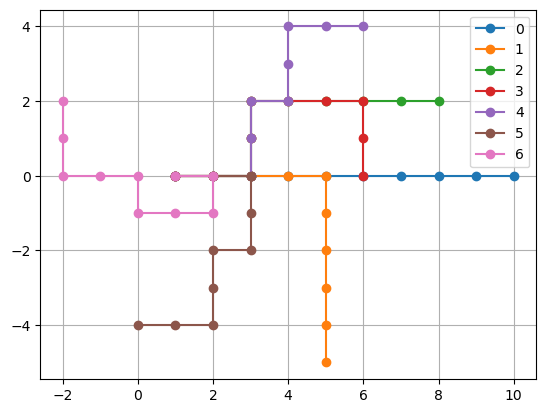

[[ 0  0]
 [ 1 -2]
 [ 1 -3]
 [ 0 -3]
 [ 0 -2]
 [ 0 -1]
 [ 1  0]
 [ 1  1]
 [ 2  1]
 [ 3  1]]


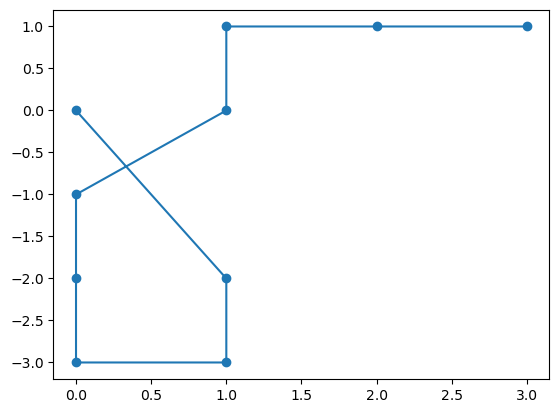

"\np0 = rotate(p0, xy, 1)\np0 = rotate(p0, xy, 0)\np0 = rotate(p0, xy, 0)\np0 = rotate(p0, (3, 0), 0)\np0 = rotate(p0, (4, 0), 1)\n\nif type(coord) == int:\n    monomer_id = coord\nelse:\n    monomer_id = polymer['id'][np.where((polymer['position'] == coord).all(axis=1))[0][0]]\n\nN = len(polymer['id'])\nreference_position = polymer[monomer_id]['position']\npositions = polymer['position'][monomer_id:]\nrelative_positions = positions - reference_position\nrotated_positions = np.dot(relative_positions, R)\npolymer['position'][monomer_id:] = rotated_positions + reference_position\nreturn polymer\n"

In [230]:
import numpy as np
import matplotlib.pyplot as plt

# Initialiserer polymeret med N monomerer
init_polymer = lambda N: np.array([[i + 1, 0] for i in range(N)]) 

p0 = init_polymer(10) 
plt.plot(p0[:, 0], p0[:, 1], "o-", label="0")

"""
Roterer polymeret polymer omkring xy med en vinkel=state.
Input:
    polymer: np.array, (N, 2)
    xy: np.array, (2,)
    state: int, 0 (+90), 1 (-90)
Output:
    np.array, (N, 2)
"""
rotate = lambda polymer, xy, state: np.append(
    polymer[np.linalg.norm(polymer, axis=1) < np.linalg.norm(xy)],
    (polymer[np.linalg.norm(polymer, axis=1) >= np.linalg.norm(xy, axis=0)] - xy)
    @ np.array([[0, 1 - 2 * state], [2 * state - 1, 0]])
    + xy,
    axis=0,
)


xy = np.array([5, 0])

print(p0[np.linalg.norm(p0, axis=1) < np.linalg.norm(xy)])
print(np.linalg.norm(p0, axis=1))
p0 = rotate(p0, xy, 1)
plt.plot(p0[:, 0], p0[:, 1], "o-", label="1")

p0 = rotate(p0, (3, 0), 0)
plt.plot(p0[:, 0], p0[:, 1], "o-", label="2")
p0 = rotate(p0, (6, 2), 1)
plt.plot(p0[:, 0], p0[:, 1], "o-", label="3")
p0 = rotate(p0, (4, 2), 0)
print(p0)
plt.plot(p0[:, 0], p0[:, 1], "o-", label="4")
p0 = rotate(p0, (3, 0), 1)
p0 = rotate(p0, (3, 0), 1)
plt.plot(p0[:, 0], p0[:, 1], "o-", label="5")
p0 = rotate(p0, (2, 0), 1)
plt.plot(p0[:, 0], p0[:, 1], "o-", label="6")
p0 = rotate(p0, (0, -1), 1)


plt.legend()
plt.grid()
plt.show()
print(p0)


def plot_polymer(polymer):
    plt.plot(polymer[:, 0], polymer[:, 1], "o-")
    plt.show()


plot_polymer(p0)

"""
p0 = rotate(p0, xy, 1)
p0 = rotate(p0, xy, 0)
p0 = rotate(p0, xy, 0)
p0 = rotate(p0, (3, 0), 0)
p0 = rotate(p0, (4, 0), 1)

if type(coord) == int:
    monomer_id = coord
else:
    monomer_id = polymer['id'][np.where((polymer['position'] == coord).all(axis=1))[0][0]]

N = len(polymer['id'])
reference_position = polymer[monomer_id]['position']
positions = polymer['position'][monomer_id:]
relative_positions = positions - reference_position
rotated_positions = np.dot(relative_positions, R)
polymer['position'][monomer_id:] = rotated_positions + reference_position
return polymer
"""